# MACHINE LEARNING PROJECT

## IMPORT LIBRARY

In [58]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve,
                             mean_absolute_error, mean_squared_error, r2_score)

## MEMBACA DATASET

In [59]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
df = pd.read_csv("04_bank_customers.csv", sep=";")


In [61]:
print("Jumlah baris & kolom :", df.shape)


Jumlah baris & kolom : (45211, 17)


In [62]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## EDA (Exploratory Data Analysis)

In [5]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [9]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [63]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

df.describe(exclude="number").T      


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


In [12]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [17]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

kolom_kategori_semua = df.select_dtypes(exclude="number").columns.drop("y")
unknown = pd.DataFrame({
    "jumlah_unknown": [(df[c] == "unknown").sum() for c in kolom_kategori_semua]
}, index=kolom_kategori_semua)
unknown["persen"] = (unknown["jumlah_unknown"] / len(df) * 100).round(2)
unknown


,jumlah_unknown,persen
job,288,0.64
marital,0,0.00
education,1857,4.11
default,0,0.00
housing,0,0.00
loan,0,0.00
contact,13020,28.80
month,0,0.00
poutcome,36959,81.75


## Distribusi Variabel Target (y)

y
no     39922
yes     5289
Name: count, dtype: int64

y
no     88.3 %
yes    11.7 %
Name: proportion, dtype: str


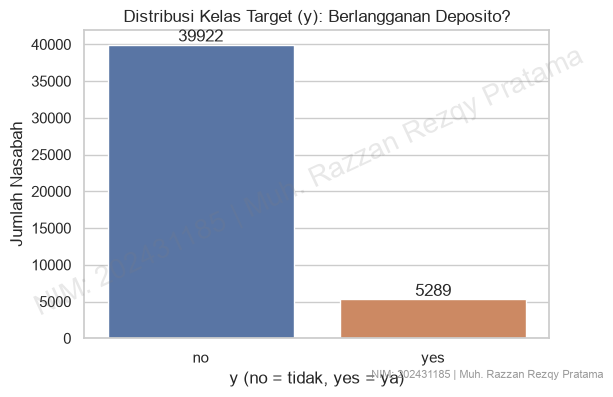

In [64]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

print(df["y"].value_counts())
print()
print((df["y"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="y", hue="y", data=df, legend=False)
for container in ax.containers:
    ax.bar_label(container)            # menampilkan angka di atas batang
plt.title("Distribusi Kelas Target (y): Berlangganan Deposito?")
plt.xlabel("y (no = tidak, yes = ya)")
plt.ylabel("Jumlah Nasabah")
tampil()


## Distribusi Variabel Numerik (Histrogram)


Kolom numerik: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


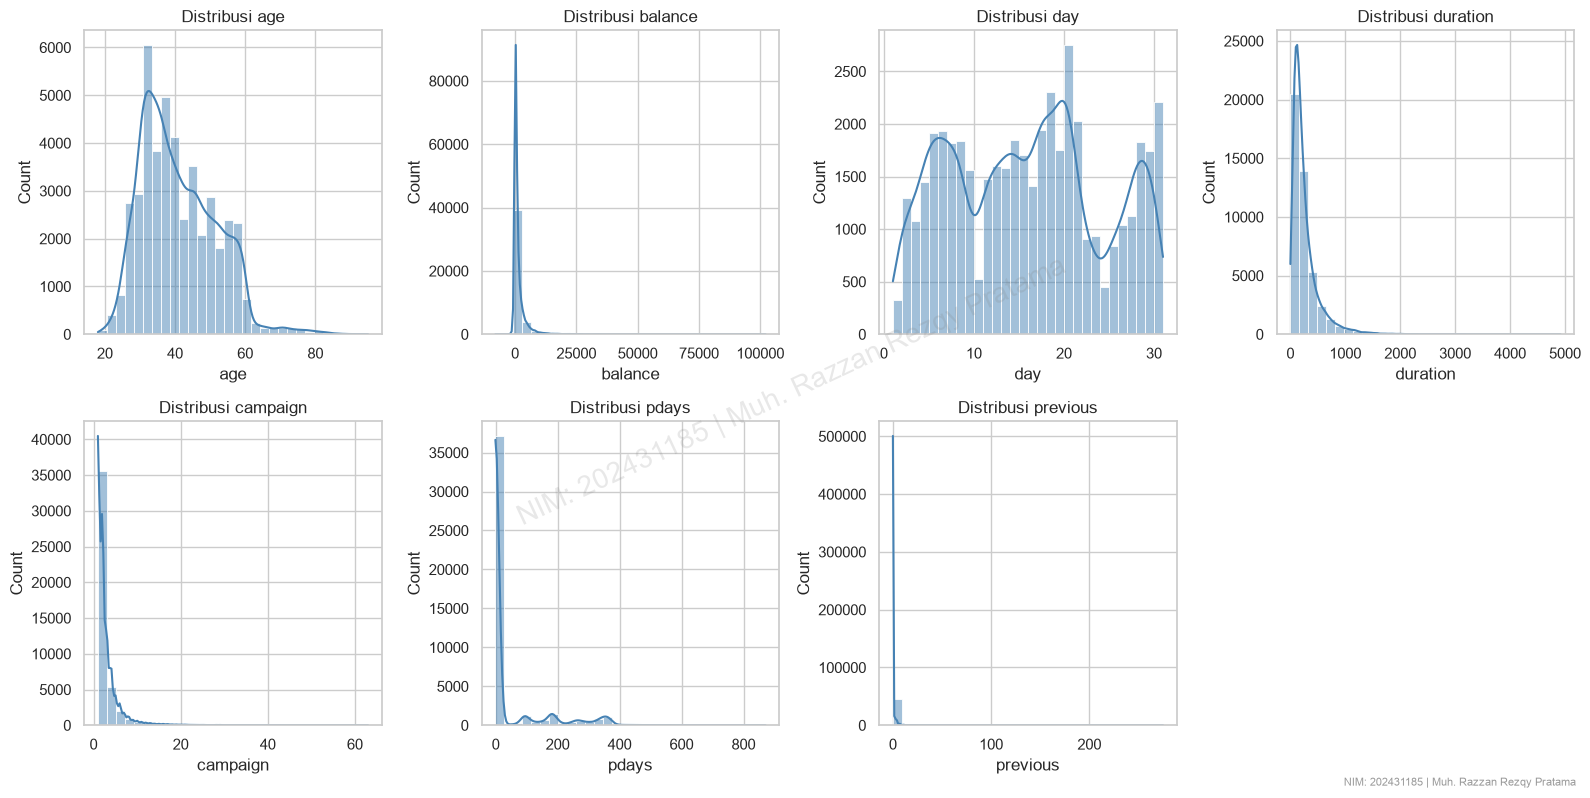

In [19]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
kolom_numerik = df.select_dtypes(include="number").columns.tolist()
print("Kolom numerik:", kolom_numerik)

plt.figure(figsize=(16, 8))
for i, col in enumerate(kolom_numerik):
    plt.subplot(2, 4, i + 1)
    sns.histplot(df[col], bins=30, kde=True, color="steelblue")
    plt.title(f"Distribusi {col}")
plt.tight_layout()
tampil()

## Deteksi Outlier

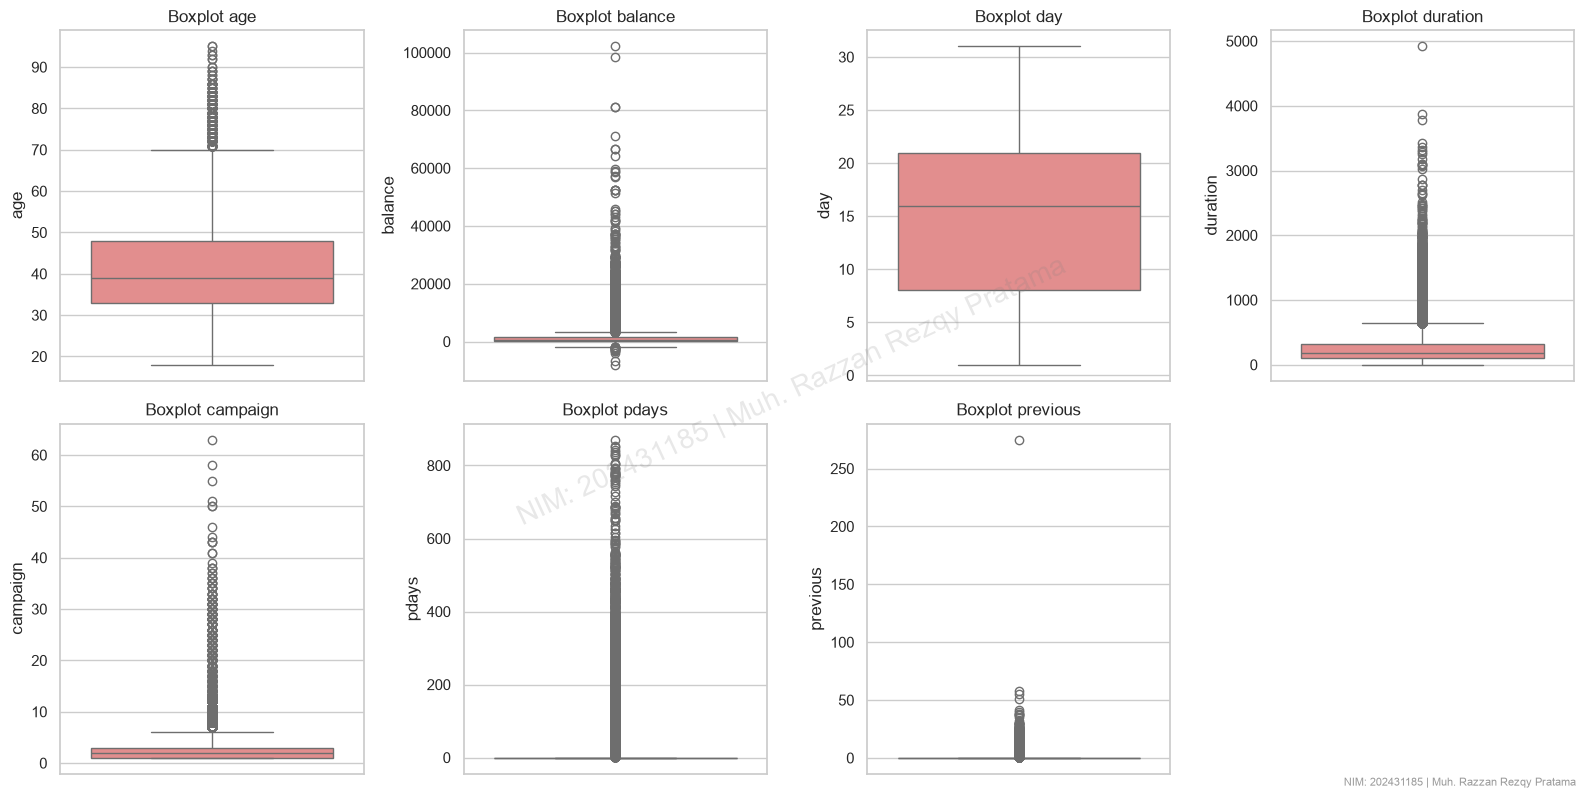

In [65]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

plt.figure(figsize=(16, 8))
for i, col in enumerate(kolom_numerik):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(y=df[col], color="lightcoral")
    plt.title(f"Boxplot {col}")
plt.tight_layout()
tampil()

In [22]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

baris = []
for col in kolom_numerik:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah, batas_atas = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    jumlah = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
    baris.append([col, Q1, Q3, batas_bawah, batas_atas, jumlah, round(jumlah / len(df) * 100, 2)])

tabel_outlier = pd.DataFrame(baris, columns=["kolom", "Q1", "Q3", "batas_bawah", "batas_atas", "jumlah_outlier", "persen"])
tabel_outlier

,kolom,Q1,Q3,batas_bawah,batas_atas,jumlah_outlier,persen
0,age,33.0,48.0,10.5,70.5,487,1.08
1,balance,72.0,1428.0,-1962.0,3462.0,4729,10.46
2,day,8.0,21.0,-11.5,40.5,0,0.00
3,duration,103.0,319.0,-221.0,643.0,3235,7.16
4,campaign,1.0,3.0,-2.0,6.0,3064,6.78
5,pdays,-1.0,-1.0,-1.0,-1.0,8257,18.26
6,previous,0.0,0.0,0.0,0.0,8257,18.26


## Korelasi Antar Variabel Numerik 

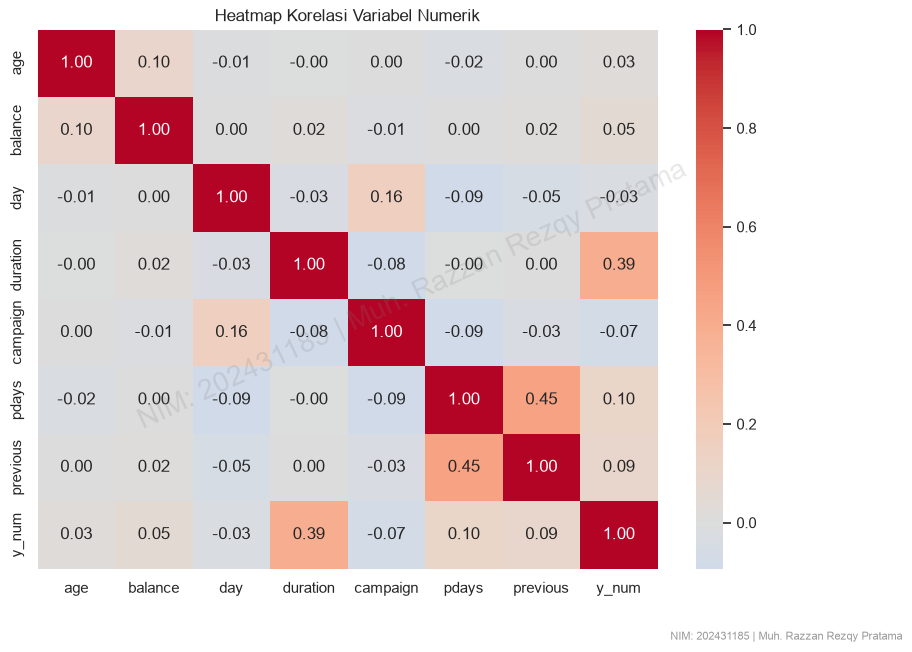

In [66]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

# y diubah sementara menjadi angka 0/1 agar korelasinya dengan variabel numerik bisa dilihat
df_korelasi = df[kolom_numerik].assign(y_num=(df["y"] == "yes").astype(int))

plt.figure(figsize=(10, 7))
sns.heatmap(df_korelasi.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap Korelasi Variabel Numerik")
tampil()


## Hubungan Variabel Kategorikal dan Numerik  dengan Target

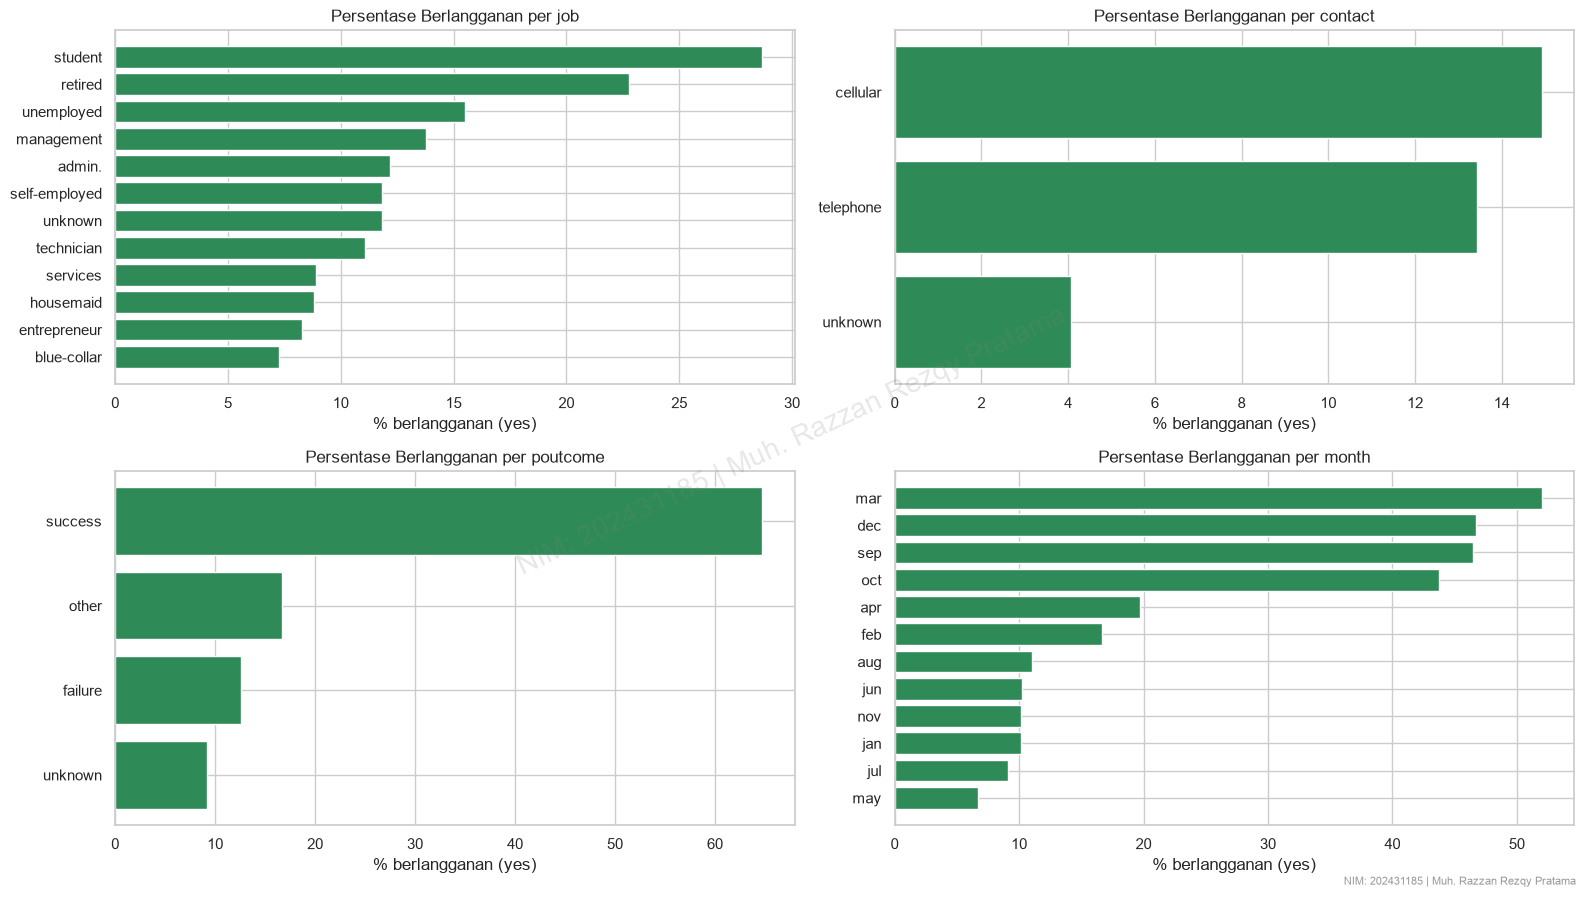

In [25]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

kolom_plot = ["job", "contact", "poutcome", "month"]
plt.figure(figsize=(16, 9))
for i, col in enumerate(kolom_plot):
    plt.subplot(2, 2, i + 1)
    # persentase nasabah yang berlangganan (y = yes) pada tiap kategori
    rate = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values()
    plt.barh(rate.index, rate.values, color="seagreen")
    plt.title(f"Persentase Berlangganan per {col}")
    plt.xlabel("% berlangganan (yes)")
plt.tight_layout()
tampil()


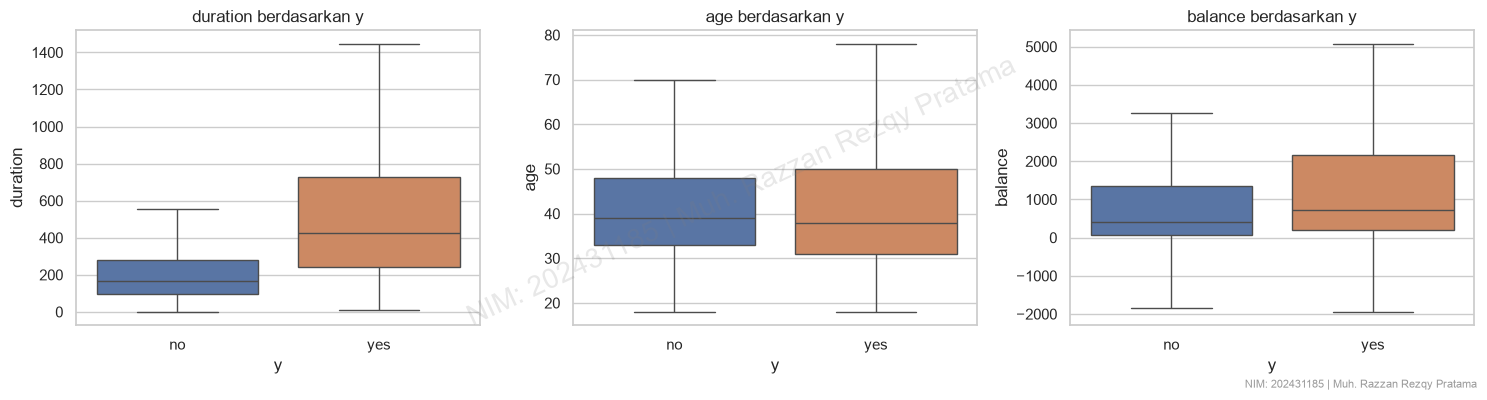

In [67]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

plt.figure(figsize=(15, 4))
for i, col in enumerate(["duration", "age", "balance"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x="y", y=col, hue="y", data=df, showfliers=False, legend=False)   
    plt.title(f"{col} berdasarkan y")
plt.tight_layout()
tampil()

## Preprocessing Data

In [31]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

df_model = df.drop_duplicates().copy()                    # 1. buang duplikat (hasilnya tidak ada yang terbuang)
df_model["y"] = df_model["y"].map({"no": 0, "yes": 1})    # 4. target menjadi angka
print("Ukuran data setelah dibersihkan:", df_model.shape)
print(df_model["y"].value_counts())
df_model.head()


Ukuran data setelah dibersihkan: (45211, 17)
y
0    39922
1     5289
Name: count, dtype: int64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


In [33]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
# Daftar kolom kategorikal & numerik untuk model klasifikasi (Decision Tree)
fitur_kategori = ["job", "marital", "education", "default", "housing",
                  "loan", "contact", "month", "poutcome"]
fitur_numerik  = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

X = df_model.drop(columns="y")       # fitur
y = df_model["y"]                    # target

# stratify=y: proporsi yes/no di data latih & uji dibuat sama dengan data asli
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi yes (data latih):", round(y_train.mean() * 100, 2), "%")
print("Proporsi yes (data uji)  :", round(y_test.mean() * 100, 2), "%")


X_train: (36168, 16) | X_test: (9043, 16)
Proporsi yes (data latih): 11.7 %
Proporsi yes (data uji)  : 11.7 %


In [68]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

preprocessor_dt = ColumnTransformer([
    ("kategori", OneHotEncoder(handle_unknown="ignore"), fitur_kategori),
    ("numerik", "passthrough", fitur_numerik)
])

preprocessor_dt.fit(X_train)
print("Jumlah fitur sebelum encoding :", X_train.shape[1])
print("Jumlah fitur setelah encoding :", len(preprocessor_dt.get_feature_names_out()))

Jumlah fitur sebelum encoding : 16
Jumlah fitur setelah encoding : 51


## Decision Tree

In [36]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

pipe_dt_awal = Pipeline([
    ("prep", preprocessor_dt),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))   # tanpa max_depth
])
pipe_dt_awal.fit(X_train, y_train)

acc_train_awal = accuracy_score(y_train, pipe_dt_awal.predict(X_train))
acc_test_awal  = accuracy_score(y_test,  pipe_dt_awal.predict(X_test))
print(f"Kedalaman pohon  : {pipe_dt_awal['model'].get_depth()}")
print(f"Jumlah daun      : {pipe_dt_awal['model'].get_n_leaves()}")
print(f"Akurasi data latih: {acc_train_awal * 100:.2f}%")
print(f"Akurasi data uji  : {acc_test_awal * 100:.2f}%")


Kedalaman pohon  : 34
Jumlah daun      : 2876
Akurasi data latih: 100.00%
Akurasi data uji  : 87.37%


In [38]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 7, 9],
    "model__min_samples_leaf": [1, 10, 50],
}
grid = GridSearchCV(
    Pipeline([("prep", preprocessor_dt),
              ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Parameter terbaik :", grid.best_params_)
print(f"F1-score CV terbaik: {grid.best_score_:.4f}")
model_dt = grid.best_estimator_        # model terbaik hasil tuning


Parameter terbaik : {'model__criterion': 'gini', 'model__max_depth': 7, 'model__min_samples_leaf': 1}
F1-score CV terbaik: 0.4840


In [69]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

y_pred_dt  = model_dt.predict(X_test)
y_proba_dt = model_dt.predict_proba(X_test)[:, 1]      # probabilitas kelas yes

acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Akurasi data latih : {accuracy_score(y_train, model_dt.predict(X_train)) * 100:.2f}%")
print(f"Akurasi data uji   : {acc_dt * 100:.2f}%")
print(f"Precision (yes)    : {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall (yes)       : {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1-score (yes)     : {f1_score(y_test, y_pred_dt):.4f}")
print(f"ROC-AUC            : {roc_auc_score(y_test, y_proba_dt):.4f}")
print()
print(classification_report(y_test, y_pred_dt, target_names=["no", "yes"]))


Akurasi data latih : 91.15%
Akurasi data uji   : 89.86%
Precision (yes)    : 0.6083
Recall (yes)       : 0.3743
F1-score (yes)     : 0.4634
ROC-AUC            : 0.8629

              precision    recall  f1-score   support

          no       0.92      0.97      0.94      7985
         yes       0.61      0.37      0.46      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.67      0.70      9043
weighted avg       0.88      0.90      0.89      9043



[[7730  255]
 [ 662  396]]


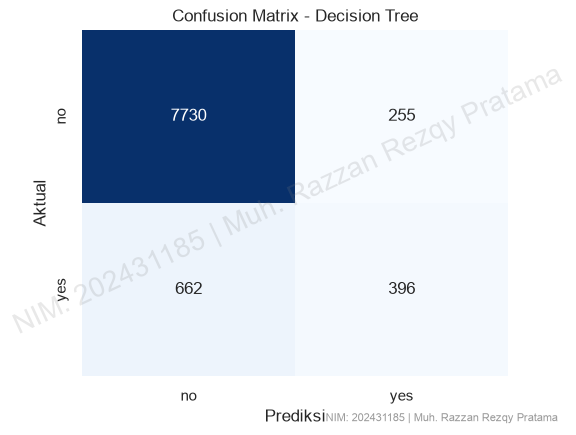

In [41]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

cm = confusion_matrix(y_test, y_pred_dt)
print(cm)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["no", "yes"], yticklabels=["no", "yes"])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix - Decision Tree")
tampil()

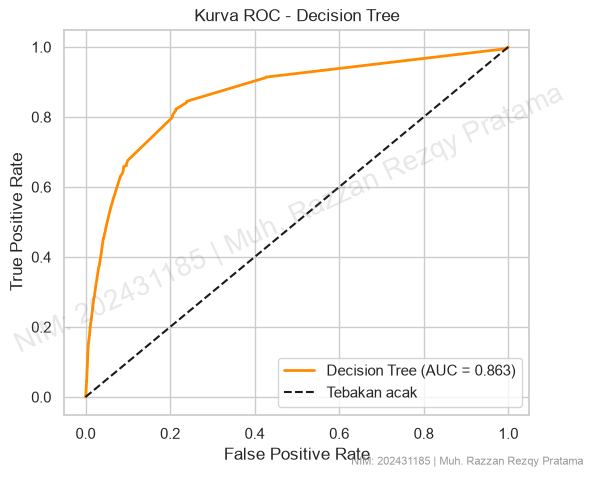

In [42]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

fpr, tpr, _ = roc_curve(y_test, y_proba_dt)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Decision Tree (AUC = {roc_auc_score(y_test, y_proba_dt):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC - Decision Tree")
plt.legend()
tampil()

duration            0.4846
poutcome_success    0.2536
pdays               0.0462
housing_no          0.0400
age                 0.0386
month_mar           0.0222
month_apr           0.0215
day                 0.0212
balance             0.0149
contact_unknown     0.0099
dtype: float64


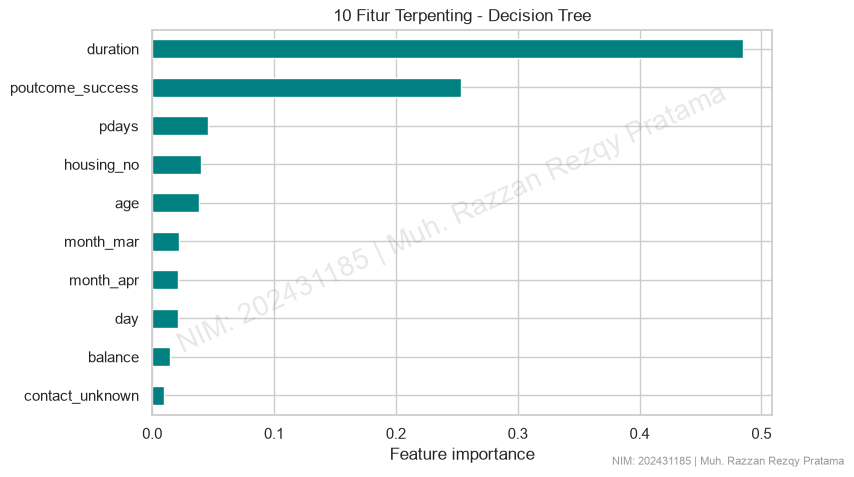

In [43]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

nama_fitur = [n.split("__", 1)[1] for n in model_dt["prep"].get_feature_names_out()]   # buang awalan "kategori__"/"numerik__"
pentingnya = pd.Series(model_dt["model"].feature_importances_, index=nama_fitur).sort_values(ascending=False)
print(pentingnya.head(10).round(4))

plt.figure(figsize=(8, 5))
pentingnya.head(10).sort_values().plot(kind="barh", color="teal")
plt.title("10 Fitur Terpenting - Decision Tree")
plt.xlabel("Feature importance")
tampil()


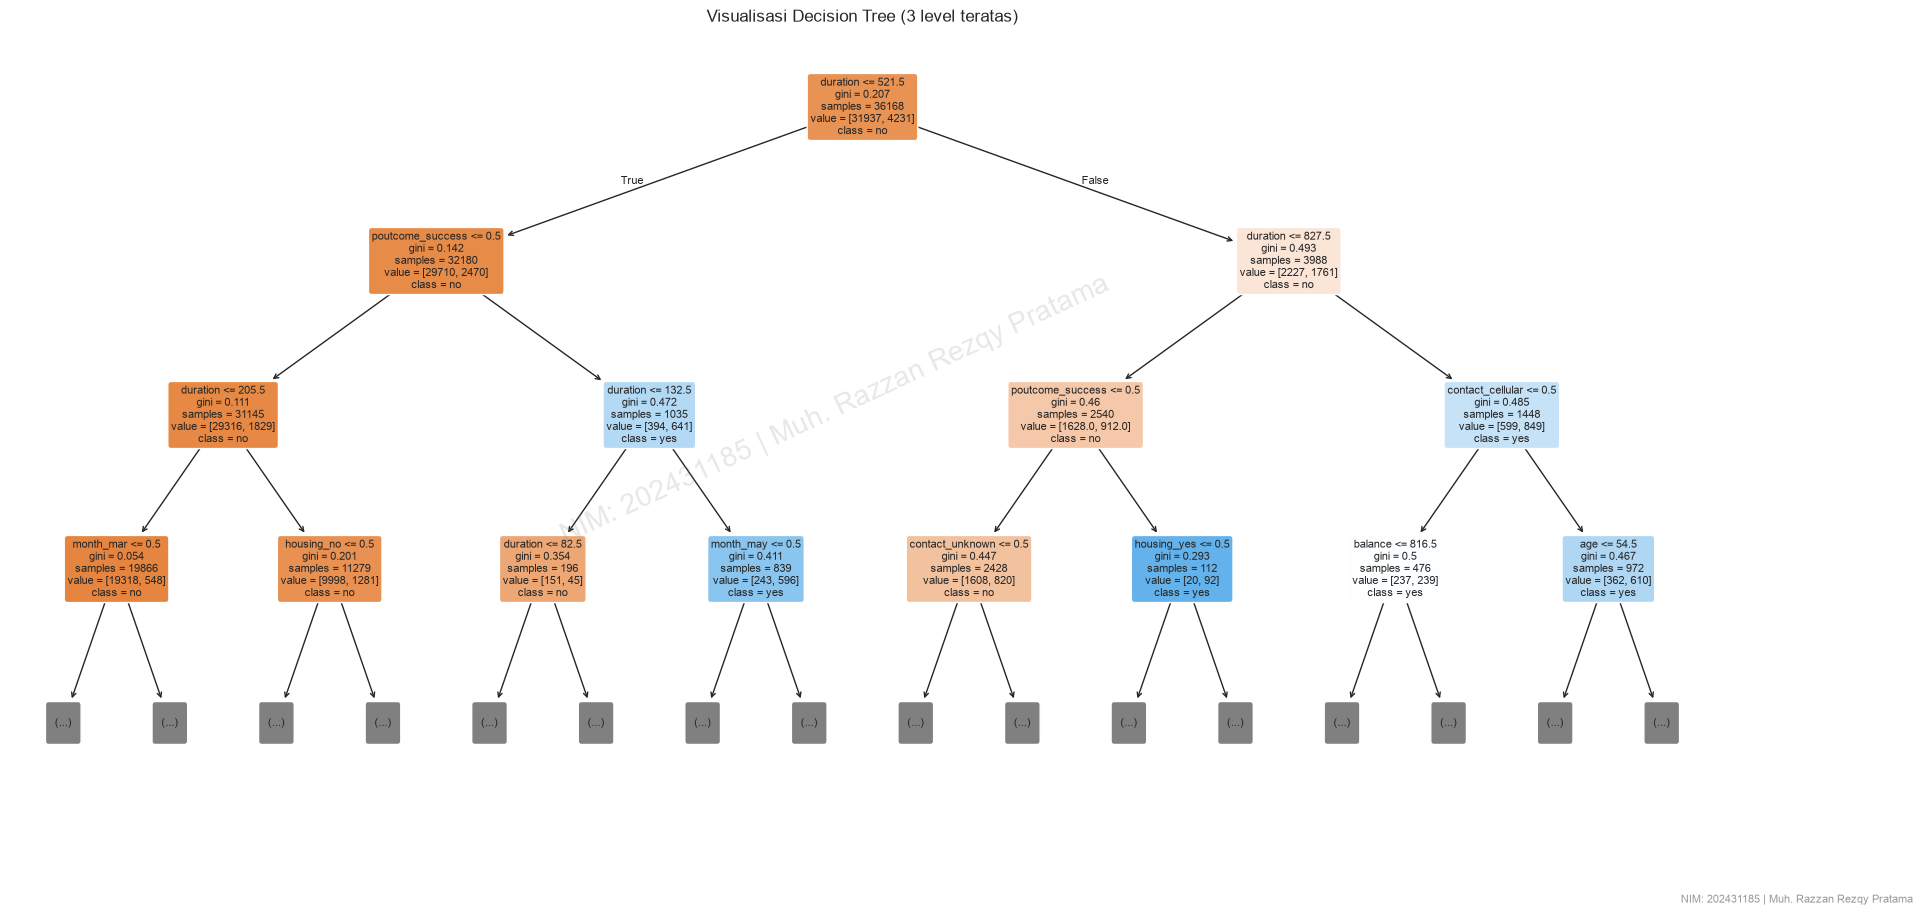

In [44]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

plt.figure(figsize=(22, 10))
plot_tree(model_dt["model"], max_depth=3,             # hanya 3 level teratas supaya terbaca
          feature_names=nama_fitur, class_names=["no", "yes"],
          filled=True, rounded=True, fontsize=8)
plt.title("Visualisasi Decision Tree (3 level teratas)")
tampil()


In [46]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

def latih_dt(buang=None):
    """Melatih Decision Tree dengan parameter terbaik, dengan opsi membuang kolom tertentu."""
    buang = buang or []
    kat = [c for c in fitur_kategori if c not in buang]
    num = [c for c in fitur_numerik if c not in buang]
    pipe = Pipeline([
        ("prep", ColumnTransformer([("kategori", OneHotEncoder(handle_unknown="ignore"), kat),
                                    ("numerik", "passthrough", num)])),
        ("model", DecisionTreeClassifier(
            criterion=grid.best_params_["model__criterion"],
            max_depth=grid.best_params_["model__max_depth"],
            min_samples_leaf=grid.best_params_["model__min_samples_leaf"],
            random_state=RANDOM_STATE))
    ])
    pipe.fit(X_train, y_train)
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    return [accuracy_score(y_test, pred), precision_score(y_test, pred),
            recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, proba)]

perbandingan = pd.DataFrame(
    [latih_dt(), latih_dt(["duration"])],
    columns=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    index=["Dengan duration", "Tanpa duration"]).round(4)
perbandingan


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Dengan duration,0.8986,0.6083,0.3743,0.4634,0.8629
Tanpa duration,0.8930,0.6148,0.2278,0.3324,0.7120


In [47]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

nasabah_baru = pd.DataFrame([{
    "age": 35, "job": "management", "marital": "married", "education": "tertiary",
    "default": "no", "balance": 2500, "housing": "no", "loan": "no",
    "contact": "cellular", "day": 15, "month": "may", "duration": 400,
    "campaign": 2, "pdays": -1, "previous": 0, "poutcome": "unknown"}])

hasil = model_dt.predict(nasabah_baru)[0]
peluang = model_dt.predict_proba(nasabah_baru)[0, 1]
print("Prediksi :", "BERLANGGANAN (yes)" if hasil == 1 else "TIDAK berlangganan (no)")
print(f"Peluang berlangganan: {peluang * 100:.2f}%")


Prediksi : TIDAK berlangganan (no)
Peluang berlangganan: 12.71%


## Regresi Linear

In [70]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

print("Korelasi variabel numerik terhadap balance:")
print(df[kolom_numerik].corr()["balance"].drop("balance").sort_values().round(4))

fitur_numerik_reg = ["age", "day", "duration", "campaign", "pdays", "previous"]   
X_reg = df_model.drop(columns=["balance", "y"])
y_reg = df_model["balance"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)
print("\nX_train_r:", X_train_r.shape, "| X_test_r:", X_test_r.shape)

Korelasi variabel numerik terhadap balance:
campaign   -0.0146
pdays       0.0034
day         0.0045
previous    0.0167
duration    0.0216
age         0.0978
Name: balance, dtype: float64

X_train_r: (36168, 15) | X_test_r: (9043, 15)


In [73]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

preprocessor_lr = ColumnTransformer([
    ("kategori", OneHotEncoder(drop="first", handle_unknown="ignore"), fitur_kategori),
    ("numerik", StandardScaler(), fitur_numerik_reg)
])

model_lr = Pipeline([
    ("prep", preprocessor_lr),
    ("model", LinearRegression())
])
model_lr.fit(X_train_r, y_train_r)       # fase training
print("Model Regresi Linear berhasil dilatih.")
print("Intercept:", round(model_lr["model"].intercept_, 4))


Model Regresi Linear berhasil dilatih.
Intercept: 1192.8248


In [75]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

def evaluasi(y_asli, y_prediksi):
    mse = mean_squared_error(y_asli, y_prediksi)
    return [mean_absolute_error(y_asli, y_prediksi), mse, np.sqrt(mse), r2_score(y_asli, y_prediksi)]

y_pred_train_r = model_lr.predict(X_train_r)
y_pred_r       = model_lr.predict(X_test_r)

hasil_reg = pd.DataFrame(
    [evaluasi(y_train_r, y_pred_train_r), evaluasi(y_test_r, y_pred_r)],
    columns=["MAE", "MSE", "RMSE", "R2"],
    index=["Data latih", "Data uji"]).round(4)
hasil_reg


,MAE,MSE,RMSE,R2
Data latih,1475.6531,8.673723e+06,2945.1186,0.0509
Data uji,1486.8634,9.338625e+06,3055.9165,0.0468


[ NIM: 202431185 | Muh. Razzan Rezqy Pratama ]


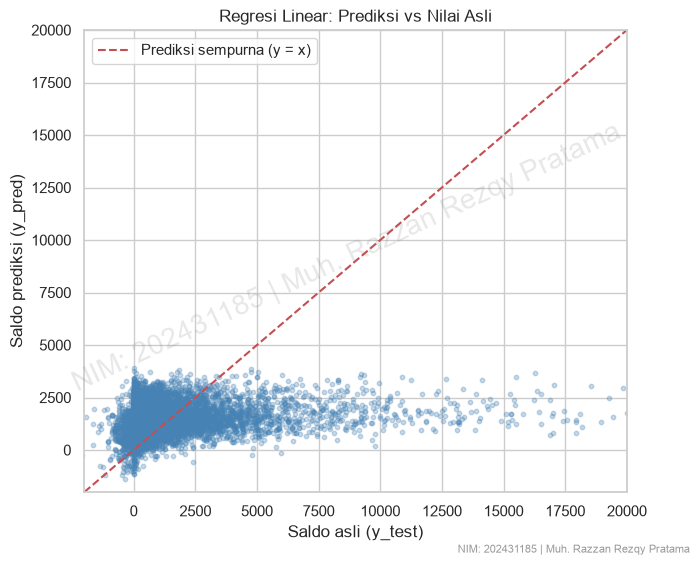

In [52]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama
cetak_wm()
plt.figure(figsize=(7, 6))
plt.scatter(y_test_r, y_pred_r, alpha=0.3, s=10, color="steelblue")
plt.plot([-2000, 20000], [-2000, 20000], "r--", label="Prediksi sempurna (y = x)")
plt.xlim(-2000, 20000)
plt.ylim(-2000, 20000)         # sumbu dibatasi agar sebaran mayoritas data terlihat
plt.xlabel("Saldo asli (y_test)")
plt.ylabel("Saldo prediksi (y_pred)")
plt.title("Regresi Linear: Prediksi vs Nilai Asli")
plt.legend()
tampil()


Rata-rata residual : -7.56
Median residual    : -661.60


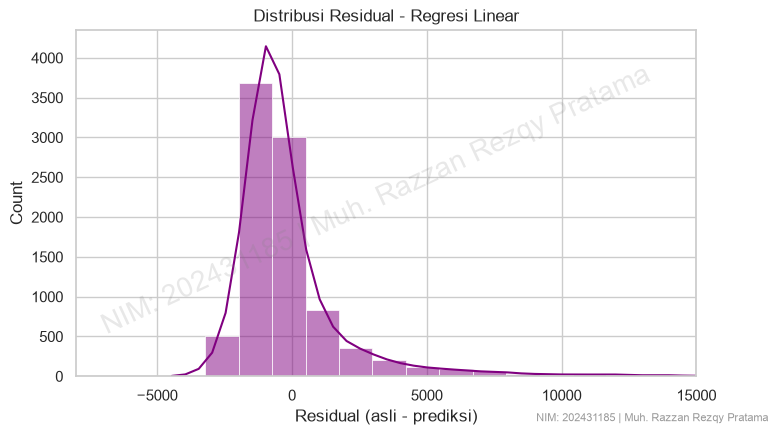

In [53]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

residual = y_test_r - y_pred_r        # selisih nilai asli dan prediksi
print(f"Rata-rata residual : {residual.mean():.2f}")
print(f"Median residual    : {residual.median():.2f}")

plt.figure(figsize=(8, 4.5))
sns.histplot(residual, bins=80, kde=True, color="purple")
plt.xlim(-8000, 15000)
plt.title("Distribusi Residual - Regresi Linear")
plt.xlabel("Residual (asli - prediksi)")
tampil()


default_yes          -1286.93
month_nov              798.11
month_jan             -783.95
month_jul             -589.79
loan_yes              -539.42
education_tertiary     464.17
month_oct              420.15
marital_single         399.12
month_aug             -365.99
month_feb             -329.47
dtype: float64


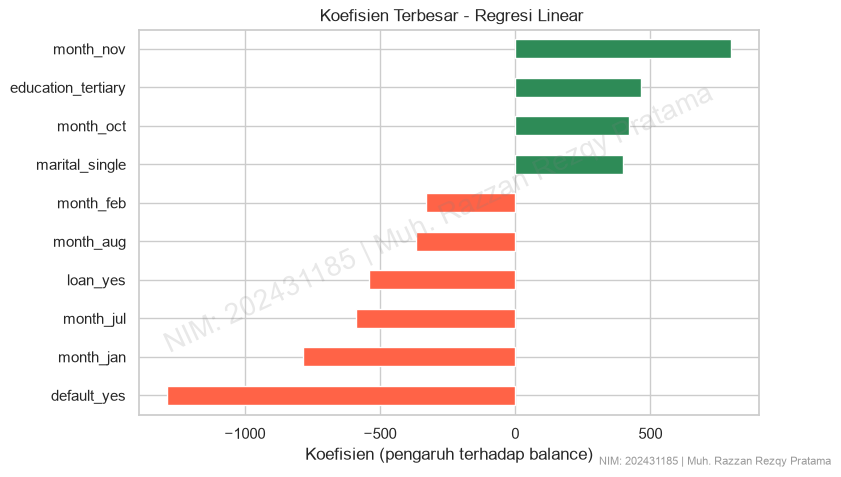

In [55]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

nama_fitur_r = [n.split("__", 1)[1] for n in model_lr["prep"].get_feature_names_out()]
koefisien = pd.Series(model_lr["model"].coef_, index=nama_fitur_r)
top = koefisien.reindex(koefisien.abs().sort_values(ascending=False).index).head(10)
print(top.round(2))

plt.figure(figsize=(8, 5))
top.sort_values().plot(kind="barh", color=["tomato" if v < 0 else "seagreen" for v in top.sort_values()])
plt.title(" Koefisien Terbesar - Regresi Linear")
plt.xlabel("Koefisien (pengaruh terhadap balance)")
tampil()


In [76]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

nasabah_reg = nasabah_baru.drop(columns="balance")     
prediksi_saldo = model_lr.predict(nasabah_reg)[0]
print(f"Prediksi saldo nasabah: {prediksi_saldo:,.2f} euro")


Prediksi saldo nasabah: 1,760.23 euro


## Rangkuman hasil

In [57]:
# NIM: 202431185 | Muh. Razzan Rezqy Pratama

rangkuman = pd.DataFrame({
    "Algoritma": ["Decision Tree (klasifikasi)", "Regresi Linear (regresi)"],
    "Target": ["y (berlangganan deposito)", "balance (saldo nasabah)"],
    "Metrik utama (data uji)": [f"Accuracy = {acc_dt * 100:.2f}%", f"R2 = {r2_score(y_test_r, y_pred_r):.4f}"],
    "Metrik pendukung": [f"F1 = {f1_score(y_test, y_pred_dt):.3f}; ROC-AUC = {roc_auc_score(y_test, y_proba_dt):.3f}",
                         f"MAE = {mean_absolute_error(y_test_r, y_pred_r):.1f}; RMSE = {np.sqrt(mean_squared_error(y_test_r, y_pred_r)):.1f}"]
})
rangkuman

,Algoritma,Target,Metrik utama (data uji),Metrik pendukung
0,Decision Tree (klasifikasi),y (berlangganan deposito),Accuracy = 89.86%,F1 = 0.463; ROC-AUC = 0.863
1,Regresi Linear (regresi),balance (saldo nasabah),R2 = 0.0468,MAE = 1486.9; RMSE = 3055.9
